In [3]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !apt-get -qq update
    !apt-get -qq install -y x11-utils python3-opengl xvfb
    !pip -q install vmas pyvirtualdisplay
    import pyvirtualdisplay
    display = pyvirtualdisplay.Display(visible=False, size=(1400, 900))
    display.start()

In [4]:
import torch
from torch import Tensor

from vmas import make_env
from vmas.simulator.core import Agent, Landmark, Sphere, World
from vmas.simulator.scenario import BaseScenario
from vmas.simulator.utils import Color, ScenarioUtils

torch.manual_seed(0)
DEVICE = "cpu"  # use "cuda" if you have a GPU

| Setting | Default | What it does |
|---|---|---|
| `n_agents` | 4 | Number of robots |
| `n_pois` | 3 | Number of POIs |
| `agents_per_poi` | 2 | Robots needed on a POI at the same time to catch it |
| `arena_size` | 1.0 | Half the width of the arena. 1.0 means it goes from -1 to 1 |
| `sensing_range` | 0.35 | How far a robot can see POIs and teammates |
| `dim_c` | 4 | How many numbers are in a message. 0 = no messages |
| `comm_range` | 1.0 | How far messages travel |
| `comm_dropout` | 0.0 | Chance a message gets lost (0.3 = 30% lost) |
| `comm_noise` | 0.0 | Random noise added to messages |
| `capture_range` | 0.15 | How close a robot must be to count as "on" a POI |
| `capture_reward` | 1.0 | Points for the team per POI caught |
| `closer_reward_weight` | 1.0 | How much robots get for moving closer to POIs. 0 turns it off |
| `time_penalty` | -0.01 | Small cost every step, so faster is better |
| `collision_penalty` | -0.1 | Penalty for bumping into a teammate |

## Building the environment

In [5]:
class Scenario(BaseScenario):
    def make_world(self, batch_dim, device, **kwargs):
        raise NotImplementedError()

    def reset_world_at(self, env_index):
        raise NotImplementedError()

    def observation(self, agent):
        raise NotImplementedError()

    def reward(self, agent):
        raise NotImplementedError()

### `make_world`

In [29]:
def make_world(self, batch_dim: int, device: torch.device, **kwargs):
    
    self.n_agents = kwargs.pop("n_agents", 4)
    self.n_pois = kwargs.pop("n_pois", 5)
    self.agents_per_poi = kwargs.pop("agents_per_poi", 2)
    self.arena_size = kwargs.pop("arena_size", 1.0)
    self.sensing_range = kwargs.pop("sensing_range", 0.35)

    self.dim_c = kwargs.pop("dim_c", 4)
    self.comm_range = kwargs.pop("comm_range", 0.8)
    self.comm_dropout = kwargs.pop("comm_dropout", 0.0)
    self.comm_noise = kwargs.pop("comm_noise", 0.0)

    self.capture_range = kwargs.pop("capture_range", 0.15)
    self.capture_reward = kwargs.pop("capture_reward", 1.0)
    self.closer_reward_weight = kwargs.pop("closer_reward_weight", 1.0)
    self.time_penalty = kwargs.pop("time_penalty", -0.01)
    self.collision_penalty = kwargs.pop("collision_penalty", -0.1)

    self.agent_radius = 0.05
    ScenarioUtils.check_kwargs_consumed(kwargs)  # complain about unknown settings (typos)

    # world
    world = World(
        batch_dim,
        device,
        dim_c=self.dim_c,  # message size (0 = no messages)
        x_semidim=self.arena_size,  # invisible walls
        y_semidim=self.arena_size,
    )

    # Robots
    for i in range(self.n_agents):
        robot = Agent(
            name=f"agent_{i}",
            shape=Sphere(radius=self.agent_radius),
            color=Color.BLUE,
            collide=True,
            silent=(self.dim_c == 0),  # no message actions when messages are off
            c_noise=self.comm_noise,  # fuzz added to messages
        )
        robot.collision_reward = torch.zeros(batch_dim, device=device)  # filled in by reward()
        world.add_agent(robot)

    # POIs
    self.pois = []
    for i in range(self.n_pois):
        poi = Landmark(
            name=f"poi_{i}",
            shape=Sphere(radius=0.03),
            color=Color.RED,
            collide=False,  # robots pass through POIs
        )
        world.add_landmark(poi)
        self.pois.append(poi)

    # Places to keep reward info between steps
    self.team_reward = torch.zeros(batch_dim, device=device)
    self.catches = torch.zeros(batch_dim, device=device)
    self.closer_reward = torch.zeros(batch_dim, device=device)
    self.previous_gap = torch.zeros(batch_dim, self.n_pois, device=device)

    return world


Scenario.make_world = make_world

### Helpers: measuring distances

- `_robot_poi_distances()`: the distance from every robot to every POI. It has shape `[env id, robots, POIs]`.
- `_gap_to_capture()`: for each POI, how far the 2nd closest robot is.
- `_random_spot()`: random positions inside the arena, used when a caught POI respawns.

In [7]:
def _robot_poi_distances(self) -> Tensor:
    # Shape [env id, robots, POIs]
    robot_positions = torch.stack([robot.state.pos for robot in self.world.agents], dim=1)
    poi_positions = torch.stack([poi.state.pos for poi in self.pois], dim=1)
    return torch.cdist(robot_positions, poi_positions)


def _gap_to_capture(self) -> Tensor:
    # For each POI, the distance of the k-th closest robot (k = agents_per_poi). Shape [env ids, POIs]
    distances = self._robot_poi_distances()
    sorted_distances = distances.sort(dim=1).values
    return sorted_distances[:, self.agents_per_poi - 1]


def _random_spot(self, n: int) -> Tensor:
    # n random positions inside the arena. Shape [n, 2]
    return (torch.rand(n, 2, device=self.world.device) * 2 - 1) * self.arena_size


Scenario._robot_poi_distances = _robot_poi_distances
Scenario._gap_to_capture = _gap_to_capture
Scenario._random_spot = _random_spot

### `reset_world_at`

In [8]:
def reset_world_at(self, env_index: int = None):
    ScenarioUtils.spawn_entities_randomly(
        self.world.agents + self.pois,
        self.world,
        env_index,
        min_dist_between_entities=self.agent_radius * 2 + 0.05,
        x_bounds=(-self.arena_size, self.arena_size),
        y_bounds=(-self.arena_size, self.arena_size),
    )

    # store the gaps
    if env_index is None:
        self.previous_gap = self._gap_to_capture()
    else:
        self.previous_gap[env_index] = self._gap_to_capture()[env_index]


Scenario.reset_world_at = reset_world_at

### `reward`
1. **Catches.** Count robots within `capture_range` of each POI. 2 or more → caught, and the team gets `capture_reward` per catch.
2. **Getting closer.** Catches are rare early in training, so robots also get a hint: how much each POI's gap (from 3.2) shrank since last step. Gap shrank → positive, grew → negative.
3. **Respawn.** Caught POIs jump to a random new spot. Then we recompute the gaps, so the jump doesn't count as the team suddenly falling behind.
4. **Team reward** = catches + getting closer + a small time penalty.
5. **Bumping.** Robots that bump into each other get a penalty.

In [1]:
def reward(self, agent: Agent):
    if agent == self.world.agents[0]:  # because we are doing team reward so we only do it once
        distances = self._robot_poi_distances()  # [copies, robots, POIs]

        # Catches
        robots_on_poi = (distances < self.capture_range).sum(dim=1)  # [copies, POIs]
        caught = robots_on_poi >= self.agents_per_poi  # [copies, POIs], True/False
        self.catches = caught.sum(dim=1).float()  # [copies]

        # Getting closer: how much each gap shrinks since last step
        gap = self._gap_to_capture()
        self.closer_reward = (self.previous_gap - gap).sum(dim=1) * self.closer_reward_weight

        # Respawn caught POIs to new locations
        for j, poi in enumerate(self.pois):
            new_spot = self._random_spot(self.world.batch_dim)
            was_caught = caught[:, j].unsqueeze(-1)  # [copies, 1]
            poi.set_pos(torch.where(was_caught, new_spot, poi.state.pos), batch_index=None)
        self.previous_gap = self._gap_to_capture()  # after respawning

        # Team reward
        self.team_reward = self.catches * self.capture_reward + self.closer_reward + self.time_penalty

        # Bumping penalty (only for the robots involved)
        for robot in self.world.agents:
            robot.collision_reward[:] = 0
        for i, a in enumerate(self.world.agents):
            for b in self.world.agents[i + 1 :]:
                bumped = self.world.get_distance(a, b) <= 0.005
                a.collision_reward[bumped] += self.collision_penalty
                b.collision_reward[bumped] += self.collision_penalty

    return self.team_reward + agent.collision_reward


Scenario.reward = reward

NameError: name 'Agent' is not defined

### `observation`
| Part | Numbers | What it is |
|---|---|---|
| Agent | 4 | Position (x, y) and velocity (x, y) |
| Each POI | 3 each | Where it POI relative to me (x, y), and 1/0 for "can I see it?" |
| Each teammate | 3 each | Where they are relative to me (x, y), and 1/0 for "can I see them?" |
| Each teammate's message | `dim_c` + 1 each | Their last message, and 1/0 for "did I hear it?" (only when messages are on) |

With dim_c=4: 4 + 3×3 + 3×3 + 3×(4+1) = **37 numbers**. With `dim_c=0`: **22**.

In [10]:
def observation(self, agent: Agent):
    me = agent.state.pos
    parts = [agent.state.pos, agent.state.vel]  # about me

    # POIs I can see
    for poi in self.pois:
        offset = poi.state.pos - me
        can_see = (offset.norm(dim=-1, keepdim=True) < self.sensing_range).float()  # 1 or 0
        parts += [offset * can_see, can_see]  # zeros if I can't see it

    # Teammates: where they are (if close) and what they said (if in radio range)
    for teammate in self.world.agents:
        if teammate is agent:
            continue
        offset = teammate.state.pos - me
        distance = offset.norm(dim=-1, keepdim=True)

        can_see = (distance < self.sensing_range).float()
        parts += [offset * can_see, can_see]

        if self.dim_c > 0:
            can_hear = (distance < self.comm_range).float()
            if self.comm_dropout > 0:
                not_lost = (torch.rand_like(can_hear) >= self.comm_dropout).float()
                can_hear = can_hear * not_lost
            parts += [teammate.state.c * can_hear, can_hear]  # zeros if I can't hear them

    return {
        "obs": torch.cat(parts, dim=-1),
        "pos": agent.state.pos,  # for GNNs if used
        "vel": agent.state.vel,  # for GNNs if used
    }


Scenario.observation = observation

### `info` and `extra_render`


In [11]:
def info(self, agent: Agent) -> dict:
    return {
        "catches": self.catches,
        "closer_reward": self.closer_reward,
        "collision_reward": agent.collision_reward,
    }


def extra_render(self, env_index: int = 0) -> list:
    from vmas.simulator import rendering

    def draw_circle(center, radius, color):
        circle = rendering.make_circle(radius, filled=False)
        move_to = rendering.Transform()
        move_to.set_translation(*center)
        circle.add_attr(move_to)
        circle.set_color(*color)
        return circle

    drawings = []
    for robot in self.world.agents:
        drawings.append(draw_circle(robot.state.pos[env_index], self.sensing_range, Color.GRAY.value))
    for poi in self.pois:
        drawings.append(draw_circle(poi.state.pos[env_index], self.capture_range, Color.RED.value))

    if self.dim_c > 0:
        for i, a in enumerate(self.world.agents):
            for b in self.world.agents[i + 1 :]:
                distance = (a.state.pos[env_index] - b.state.pos[env_index]).norm()
                if distance <= self.comm_range:
                    line = rendering.Line(a.state.pos[env_index], b.state.pos[env_index], width=1)
                    line.set_color(*Color.BLACK.value)
                    drawings.append(line)
    return drawings


Scenario.info = info
Scenario.extra_render = extra_render

In [25]:
env = make_env(
    scenario=Scenario(),
    num_envs=8,
    device=DEVICE,
    seed=0,
    continuous_actions=True,
    max_steps=200,  # a round lasts 200 steps
    # our settings (anything not listed uses the default)
    n_agents=4,
    n_pois=3,
    dim_c=4,
)
obs = env.reset()

print("Robots:", len(env.agents))
print("Observation shape for robot 0:", obs[0]["obs"].shape, " -> 8 envs x 37 numbers")
print(f"Action space for robot 0: {env.action_space[0]} -> 6 numbers, first 2 for x and y motion, last 4 for communication")

Robots: 4
Observation shape for robot 0: torch.Size([8, 37])  -> 8 envs x 37 numbers
Action space for robot 0: Box([-1. -1.  0.  0.  0.  0.], 1.0, (6,), float32) -> 6 numbers, first 2 for x and y motion, last 4 for communication


### Actions

In [12]:
def still_actions(env):
    # One all-zero action per robot: no push, no message
    n_numbers = env.action_space[0].shape[0]
    return [torch.zeros(env.num_envs, n_numbers) for _ in env.agents]


actions = still_actions(env)
actions[0][:, 0] = 1.0  # robot 0: push right (in every copy)
actions[0][:, 2:] = torch.tensor([1.0, 0.7, 0.3, 0.0])  # robot 0: a message

before = env.agents[0].state.pos[0].clone()
obs, rewards, dones, info = env.step(actions)
after = env.agents[0].state.pos[0]

print("Robot 0 moved from", [round(v, 3) for v in before.tolist()], "to", [round(v, 3) for v in after.tolist()])
print("Robot 0's stored message:", [round(v, 2) for v in env.agents[0].state.c[0].tolist()])

Robot 0 moved from [-0.898, -0.203] to [-0.888, -0.203]
Robot 0's stored message: [1.0, 0.7, 0.3, 0.0]


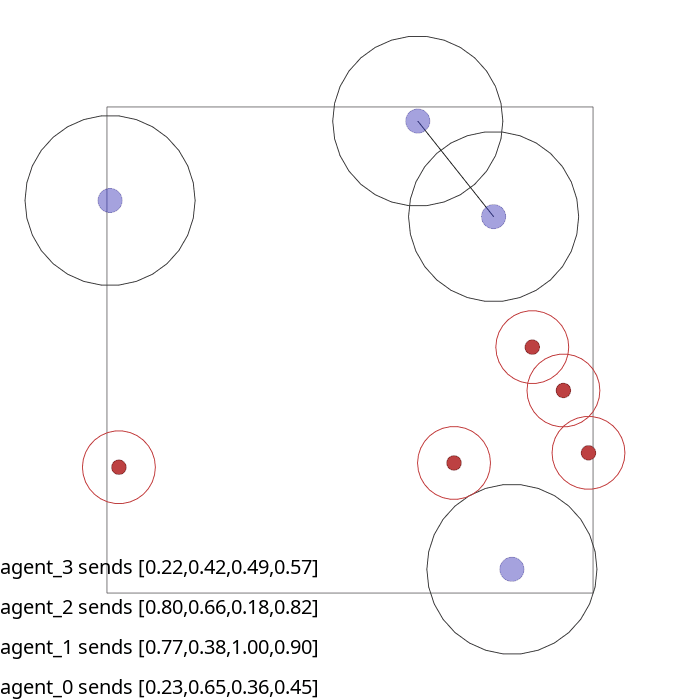

In [30]:
from IPython.display import Image as ShowImage
from PIL import Image


def make_gif(env, policy, steps, filename, fps=20):
    obs = env.reset()
    frames = []
    for _ in range(steps):
        obs, _, _, _ = env.step(policy(obs))
        frames.append(Image.fromarray(env.render(mode="rgb_array")))
    frames[0].save(filename, save_all=True, append_images=frames[1:], duration=1000 // fps, loop=0)
    return ShowImage(filename=filename)


gif_env = make_env(Scenario(), num_envs=1, device=DEVICE, seed=1)


def random_policy(obs):
    return [gif_env.get_random_action(robot) for robot in gif_env.agents]


make_gif(gif_env, random_policy, steps=100, filename="static_random.gif")

- **Blue** = robots, **gray rings** = what they can see.
- **Red dots** = POIs, **red rings** = catch zones.
- **Black lines** = robots that can hear each other.
- **Bottom-left text** = what each robot is "saying" (VMAS shows it automatically).